# Análise exploratória — Bank Marketing

## Objetivo
Conhecer a estrutura, a qualidade e os padrões iniciais do conjunto antes de qualquer modelagem. Esta etapa descreve os dados; não prova relações de causa e efeito e ainda não treina modelos.

## Origem e versão
Arquivo `bank-additional-full.csv`, extraído de `bank-additional.zip`, da [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/222/bank+marketing). A UCI informa 41.188 exemplos e 20 variáveis de entrada, ordenados por data (maio de 2008 a novembro de 2010). A versão e o hash do arquivo estão registrados em `data/README.md`. A UCI indica licença CC BY 4.0; mantenha a atribuição aos autores.

O separador do CSV é `;`. Na EDA, `unknown` será contado como categoria explícita e `pdays=999` será investigado como sentinela de “sem contato anterior”. A variável `duration` será exibida apenas para exploração: ela só é conhecida após a ligação e, por isso, não estará disponível no momento em que o modelo principal precisaria prever a adesão.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")

# Permite executar tanto a partir da raiz do projeto quanto da pasta notebooks.
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "bank-additional-full.csv"
FIGURES_PATH = ROOT / "results" / "figures"
FIGURES_PATH.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset não encontrado: {DATA_PATH}")

df = pd.read_csv(DATA_PATH, sep=";")
print(f"Arquivo: {DATA_PATH}")
print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")

Arquivo: C:\Users\User\Documents\Codex\2026-11-09\files-pasted-by-the-user-projeto\data\bank-additional-full.csv
Dimensões: 41,188 linhas × 21 colunas


## Primeiras linhas e estrutura

`head()` mostra alguns registros para conferirmos se a leitura faz sentido. `shape` informa linhas e colunas. O separador `;` é necessário para que as 21 colunas apareçam separadas corretamente.

In [2]:
display(df.head())
print("Colunas:")
print(list(df.columns))
print("\nTipos de dados:")
display(df.dtypes.to_frame("tipo"))

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


Colunas:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Tipos de dados:


,tipo
age,int64
job,str
marital,str
education,str
default,str
housing,str
loan,str
contact,str
month,str
day_of_week,str


## Qualidade dos dados: nulos, `unknown` e duplicatas

`NaN` representa uma célula vazia reconhecida pelo Pandas. Neste arquivo, `unknown` é texto e precisa ser contado separadamente. Por enquanto, ele será mantido como uma categoria própria: indica que a informação não foi registrada como uma categoria conhecida e não equivale automaticamente a um valor ausente numérico. A contagem e a decisão ficam registradas para a etapa de pré-processamento.

Registros duplicados são contados, mas não removidos nesta exploração. A remoção exige uma decisão documentada, pois duas linhas iguais podem representar observações legítimas.

In [3]:
print("Valores NaN por coluna (somente colunas com pelo menos um):")
missing = df.isna().sum()
display(missing[missing.gt(0)].to_frame("quantidade"))
print(f"Total de células NaN: {int(missing.sum()):,}")

unknown_counts = df.select_dtypes(exclude="number").apply(lambda col: col.eq("unknown").sum())
print("Contagem de 'unknown' por coluna (somente colunas com ocorrências):")
display(unknown_counts[unknown_counts.gt(0)].sort_values(ascending=False).to_frame("unknown"))

n_duplicates = int(df.duplicated().sum())
print(f"Registros totalmente duplicados: {n_duplicates:,} ({n_duplicates / len(df):.2%})")

Valores NaN por coluna (somente colunas com pelo menos um):


,quantidade


Total de células NaN: 0
Contagem de 'unknown' por coluna (somente colunas com ocorrências):


,unknown
default,8597
education,1731
housing,990
loan,990
job,330
marital,80


Registros totalmente duplicados: 12 (0.03%)

## Tipos e estatísticas das variáveis numéricas

`describe()` resume quantidade, média, desvio padrão, quartis e extremos. A média pode ser influenciada por valores extremos; por isso também observamos mediana (50%). Em `pdays`, o código `999` precisa ser interpretado antes de tratar a média como número de dias real.

In [4]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
print(f"Variáveis numéricas ({len(numeric_columns)}): {numeric_columns}")
display(df[numeric_columns].describe().T)

Variáveis numéricas (10): ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


## Variável-alvo e proporção das classes

A variável `y` tem duas categorias: `yes` e `no`. A barra exibe a quantidade de cada classe, e os percentuais dão contexto ao desbalanceamento. Se uma classe for muito mais comum, accuracy isolada poderá esconder um desempenho fraco na classe de interesse; por isso as etapas de modelagem também considerarão precision, recall, F1 e ROC-AUC.

,quantidade,percentual
y,,
no,36548,88.73
yes,4640,11.27


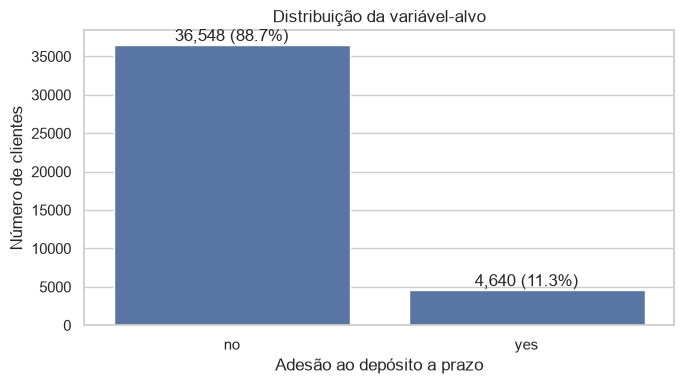

In [5]:
target_counts = df["y"].value_counts().reindex(["no", "yes"])
target_pct = df["y"].value_counts(normalize=True).reindex(["no", "yes"]) * 100
display(pd.DataFrame({"quantidade": target_counts, "percentual": target_pct.round(2)}))

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=target_counts.index, y=target_counts.values, ax=ax)
ax.set(title="Distribuição da variável-alvo", xlabel="Adesão ao depósito a prazo", ylabel="Número de clientes")
for i, value in enumerate(target_counts.values):
    ax.text(i, value, f"{value:,} ({target_pct.iloc[i]:.1f}%)", ha="center", va="bottom")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "eda_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura do gráfico:** compare o tamanho das duas classes. A diferença observada será considerada ao escolher métricas e ao interpretar o baseline na etapa de treinamento. O gráfico descreve estes dados históricos e não garante que a mesma proporção se repetirá em outra campanha.

## Distribuição de idade

O histograma mostra como as idades estão distribuídas. A linha vertical tracejada marca a mediana; isso ajuda a comparar o centro da distribuição sem depender apenas da média.

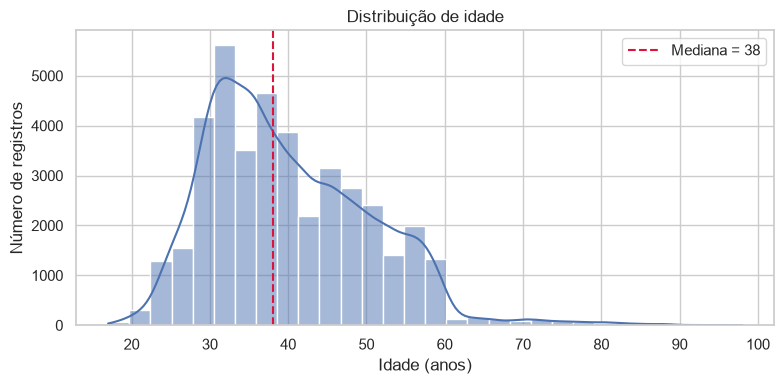

count    41188.00
mean        40.02
std         10.42
min         17.00
25%         32.00
50%         38.00
75%         47.00
max         98.00
Name: age, dtype: float64


In [6]:
age_median = df["age"].median()
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df["age"], bins=30, kde=True, ax=ax)
ax.axvline(age_median, color="crimson", linestyle="--", label=f"Mediana = {age_median:.0f}")
ax.set(title="Distribuição de idade", xlabel="Idade (anos)", ylabel="Número de registros")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_PATH / "eda_age_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(df["age"].describe().round(2))

**Leitura do gráfico:** observe onde as observações se concentram e se há uma cauda longa ou valores extremos. O histograma não informa por si só se a idade influencia causalmente a aceitação.

## Profissões mais frequentes

O gráfico apresenta as dez categorias de `job` com mais registros. A ordem facilita a comparação de frequência; não representa uma classificação de propensão à adesão.

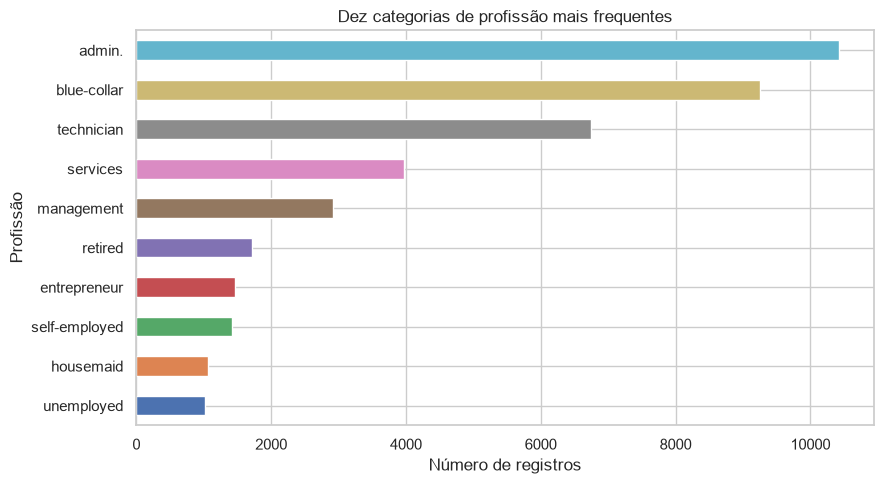

,quantidade
job,
admin.,10422
blue-collar,9254
technician,6743
services,3969
management,2924
retired,1720
entrepreneur,1456
self-employed,1421
housemaid,1060


In [7]:
job_counts = df["job"].value_counts().head(10).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
job_counts.plot(kind="barh", ax=ax, color=sns.color_palette("deep", n_colors=len(job_counts)))
ax.set(title="Dez categorias de profissão mais frequentes", xlabel="Número de registros", ylabel="Profissão")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "eda_top_jobs.png", dpi=150, bbox_inches="tight")
plt.show()
display(df["job"].value_counts(dropna=False).to_frame("quantidade"))

**Leitura do gráfico:** compare o tamanho relativo das categorias e confira a linha `unknown` na tabela. As diferenças de volume podem afetar a estabilidade das taxas por grupo, então frequência e taxa de adesão devem ser lidas separadamente.

## Escolaridade e estado civil em relação ao alvo

As barras empilhadas mostram a porcentagem de `no` e `yes` dentro de cada categoria, não o total de clientes. Essa normalização permite comparar proporções mesmo quando os grupos têm tamanhos diferentes. Categorias raras devem ser interpretadas com cautela.

y,% no,% yes
education,,
basic.4y,89.8,10.2
basic.6y,91.8,8.2
basic.9y,92.2,7.8
high.school,89.2,10.8
illiterate,77.8,22.2
professional.course,88.7,11.3
university.degree,86.3,13.7
unknown,85.5,14.5


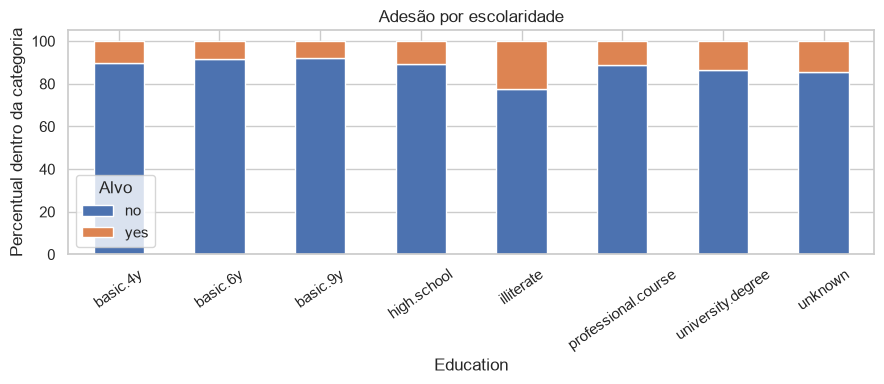

y,% no,% yes
marital,,
divorced,89.7,10.3
married,89.8,10.2
single,86.0,14.0
unknown,85.0,15.0


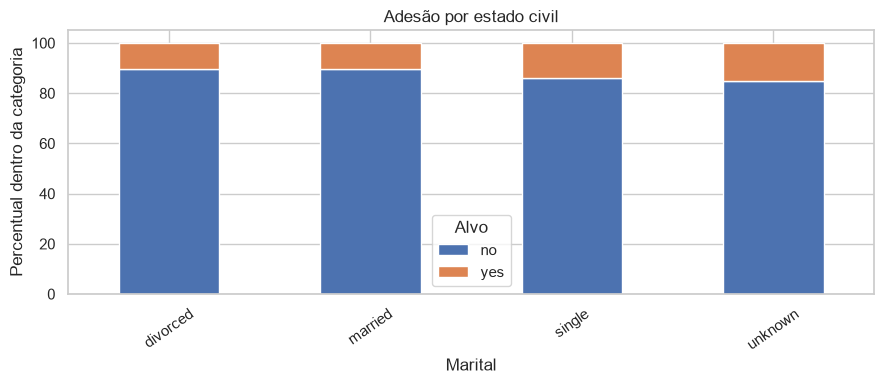

In [8]:
for column, filename, title in [
    ("education", "eda_education_by_target.png", "Adesão por escolaridade"),
    ("marital", "eda_marital_by_target.png", "Adesão por estado civil"),
]:
    rates = pd.crosstab(df[column], df["y"], normalize="index").reindex(columns=["no", "yes"], fill_value=0)
    display((rates * 100).round(1).rename(columns={"no": "% no", "yes": "% yes"}))
    ax = (rates * 100).plot(kind="bar", stacked=True, figsize=(9, 4), color=["#4C72B0", "#DD8452"])
    ax.set(title=title, xlabel=column.capitalize(), ylabel="Percentual dentro da categoria")
    ax.legend(title="Alvo")
    ax.tick_params(axis="x", rotation=35)
    fig = ax.get_figure()
    fig.tight_layout()
    fig.savefig(FIGURES_PATH / filename, dpi=150, bbox_inches="tight")
    plt.show()

**Leitura dos gráficos:** observe as diferenças percentuais entre categorias e as categorias `unknown`. Isso mostra associações descritivas na amostra. Não demonstra que escolaridade ou estado civil causem uma decisão; outras variáveis e o contexto da campanha também podem explicar diferenças.

## Número de contatos na campanha atual

`campaign` conta contatos realizados durante a campanha atual para cada cliente, incluindo o último. A distribuição costuma ter cauda; por legibilidade, o gráfico limita o eixo horizontal ao percentil 99 e informa quantos registros ficam acima desse limite.

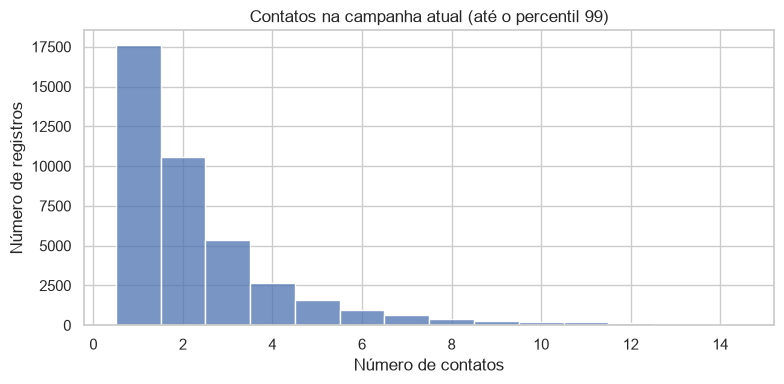

Percentil 99: 14; registros acima dele (fora do gráfico): 406


In [9]:
campaign_cap = df["campaign"].quantile(0.99)
above_cap = int(df["campaign"].gt(campaign_cap).sum())
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df.loc[df["campaign"].le(campaign_cap)], x="campaign", discrete=True, ax=ax)
ax.set(title="Contatos na campanha atual (até o percentil 99)", xlabel="Número de contatos", ylabel="Número de registros")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "eda_campaign_contacts.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Percentil 99: {campaign_cap:.0f}; registros acima dele (fora do gráfico): {above_cap:,}")

**Leitura do gráfico:** examine como a frequência de contatos se concentra e compare com o total acima do limite exibido. Frequência de contatos é informação do processo da campanha; sua utilidade para previsão será avaliada sem usar dados do conjunto de teste para ajustar o pipeline.

## Investigar `pdays=999`

Nesta versão do dataset, `999` é um código sentinela para “cliente não contatado em campanhas anteriores”, não uma duração literal. Se for tratado como 999 dias, ele pode distorcer média, escala e comparações numéricas; algoritmos sensíveis à escala ou a distância podem interpretar esse código como uma quantidade real. Na etapa de pré-processamento, criaremos uma indicação binária de contato anterior e trataremos o sentinela de forma coerente com seu significado. Aqui mantemos a coluna original apenas para a análise e quantificamos o código.

Registros com pdays = 999: 39,673 (96.32%)
Registros com outro valor de pdays: 1,515 (3.68%)
Média bruta de pdays (inclui o código 999): 962.48
Média de pdays apenas entre os previamente contatados: 6.01
Mediana apenas entre os previamente contatados: 6.00


,pdays bruto
count,41188.000000
mean,962.475454
std,186.910907
min,0.000000
25%,999.000000
50%,999.000000
75%,999.000000
max,999.000000


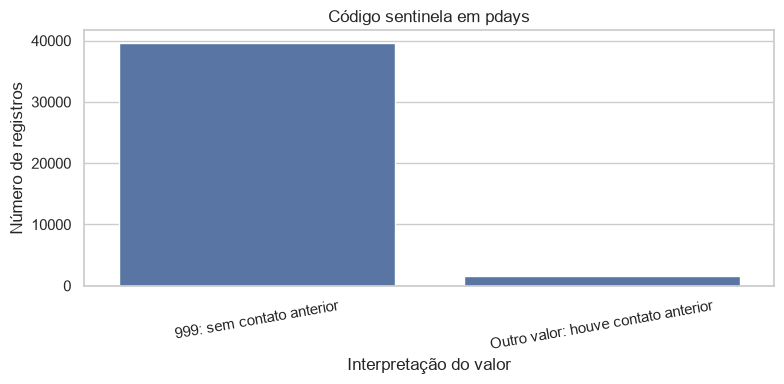

In [10]:
pdays = df["pdays"]
not_previously_contacted = pdays.eq(999)
contacted_before = ~not_previously_contacted
print(f"Registros com pdays = 999: {int(not_previously_contacted.sum()):,} ({not_previously_contacted.mean():.2%})")
print(f"Registros com outro valor de pdays: {int(contacted_before.sum()):,} ({contacted_before.mean():.2%})")
print(f"Média bruta de pdays (inclui o código 999): {pdays.mean():.2f}")
if contacted_before.any():
    print(f"Média de pdays apenas entre os previamente contatados: {pdays[contacted_before].mean():.2f}")
    print(f"Mediana apenas entre os previamente contatados: {pdays[contacted_before].median():.2f}")
display(pdays.describe().to_frame("pdays bruto"))

fig, ax = plt.subplots(figsize=(8, 4))
counts = pd.Series({"999: sem contato anterior": int(not_previously_contacted.sum()), "Outro valor: houve contato anterior": int(contacted_before.sum())})
sns.barplot(x=counts.index, y=counts.values, ax=ax)
ax.set(title="Código sentinela em pdays", xlabel="Interpretação do valor", ylabel="Número de registros")
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
fig.savefig(FIGURES_PATH / "eda_pdays_sentinel.png", dpi=150, bbox_inches="tight")
plt.show()

**Leitura do gráfico:** a barra de `999` mede quantas linhas representam ausência de contato anterior. A comparação entre a média bruta e a média apenas dos valores diferentes de 999 deixa visível por que o sentinela não deve ser descrito como 999 dias. A definição operacional da variável derivada será aplicada no pré-processamento.

## Duração da ligação — exploração, não preditor

O histograma de `duration` serve somente para entender a distribuição. A duração só é conhecida depois do contato e pode estar fortemente relacionada ao desfecho por refletir como a ligação terminou. Usá-la para escolher clientes antes de ligar seria data leakage (vazamento de informação). Portanto, ela será excluída dos preditores do modelo principal.

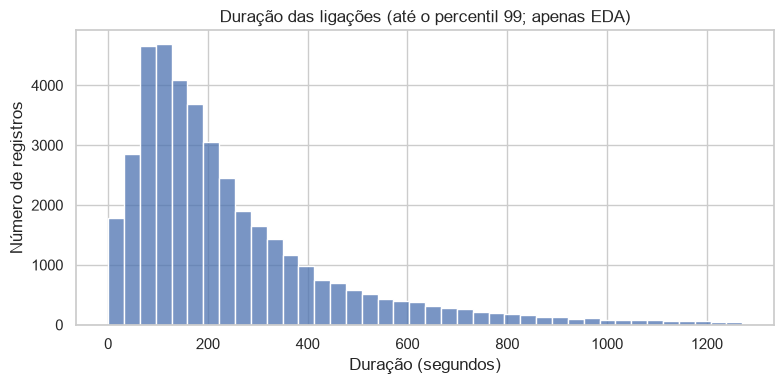

Percentil 99 da duração: 1271 s; registros acima dele: 412


In [11]:
duration_cap = df["duration"].quantile(0.99)
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=df.loc[df["duration"].le(duration_cap)], x="duration", bins=40, ax=ax)
ax.set(title="Duração das ligações (até o percentil 99; apenas EDA)", xlabel="Duração (segundos)", ylabel="Número de registros")
fig.tight_layout()
fig.savefig(FIGURES_PATH / "eda_duration_exploration_only.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Percentil 99 da duração: {duration_cap:.0f} s; registros acima dele: {int(df['duration'].gt(duration_cap).sum()):,}")

**Leitura do gráfico:** a forma da distribuição ajuda a notar a concentração e a cauda de duração. Esta visualização não autoriza usar `duration` como informação disponível antes da ligação; a coluna será removida na preparação para modelagem.

## Síntese e decisões para a próxima etapa

- O arquivo foi lido com o separador `;`; a forma, colunas e tipos foram inspecionados acima.
- `NaN`, `unknown` e duplicatas foram contabilizados separadamente. Não removemos linhas nesta etapa.
- Vamos preservar `unknown` como categoria própria, pois é um marcador explícito do dataset e não um `NaN` literal.
- `pdays=999` foi identificado como sentinela, e não como dias reais. Na preparação, será criada a informação de contato anterior e o sentinela receberá tratamento coerente.
- `duration` foi explorada visualmente, mas será excluída dos preditores por estar disponível somente depois da ligação.
- A proporção observada em `y` deve orientar as métricas; accuracy não será usada isoladamente.

As figuras salvas em `results/figures/` representam a distribuição do dataset observado e não relações causais nem garantias de desempenho futuro.